In [ ]:
import decoupler as dc
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt

c:\Users\asd123cheese\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
macro = sc.read_h5ad('../data_processed/filtered_macro_pb.h5ad')
endo = sc.read_h5ad('../data_processed/filtered_endo_pb.h5ad')

In [3]:
gobp = dc.pp.read_gmt('../data_interim/gmt/m5.go.bp.v2026.1.Mm.symbols.gmt')
hallmark = dc.pp.read_gmt('../data_interim/gmt/mh.all.v2026.1.Mm.symbols.gmt')
reactome = dc.pp.read_gmt('../data_interim/gmt/m2.cp.reactome.v2026.1.Mm.symbols.gmt')
gocc = dc.pp.read_gmt('../data_interim/gmt/m5.go.cc.v2026.1.Mm.symbols.gmt')
gomf = dc.pp.read_gmt('../data_interim/gmt/m5.go.mf.v2026.1.Mm.symbols.gmt')

In [4]:
deg_endo_heart = pd.read_excel('../data_processed/DEG_endo_heart.xlsx', index_col=0)
deg_macro_heart = pd.read_excel('../data_processed/DEG_macro_heart.xlsx', index_col=0)
deg_endo_kidney = pd.read_excel('../data_processed/DEG_endo_kidney.xlsx', index_col=0)
deg_macro_kidney = pd.read_excel('../data_processed/DEG_macro_kidney.xlsx', index_col=0)
deg_endo_liver = pd.read_excel('../data_processed/DEG_endo_liver.xlsx', index_col=0)
deg_macro_liver = pd.read_excel('../data_processed/DEG_macro_liver.xlsx', index_col=0)
deg_endo_lung = pd.read_excel('../data_processed/DEG_endo_lung.xlsx', index_col=0)
deg_macro_lung = pd.read_excel('../data_processed/DEG_macro_lung.xlsx', index_col=0)

In [5]:
def gene_set_filter(gset, min_size, max_size, name):
    gset_size = gset.groupby("source").size()
    keep = gset_size.between(min_size, max_size)
    print(f"{name}：筛选前 {len(gset_size)}，筛选后 {keep.sum()}")
    return gset.loc[gset["source"].isin(gset_size.index[keep])]

reactome, gobp, hallmark, gocc, gomf = [
    gene_set_filter(gset, 15, 200, name)
    for name, gset in (
        ("reactome", reactome),
        ("gobp", gobp),
        ("hallmark", hallmark),
        ("gocc", gocc),
        ("gomf", gomf),
    )
]

reactome：筛选前 1333，筛选后 792
gobp：筛选前 7781，筛选后 3866
hallmark：筛选前 50，筛选后 50
gocc：筛选前 1067，筛选后 485
gomf：筛选前 1899，筛选后 806


In [6]:
net = pd.concat(
    [
        hallmark.assign(collection="Hallmark"),
        reactome.assign(collection="Reactome"),
        gobp.assign(collection="GO:BP"),
        gocc.assign(collection="GO:CC"),
        gomf.assign(collection="GO:MF"),
    ],
    ignore_index=True,
)

In [7]:
def prepare_data(cell, tissue):
    deg = (
        pd.read_excel(f"../data_processed/DEG_{cell}_{tissue}.xlsx", index_col=0).set_index("variable").dropna(subset=["adj_p_value"])
    )
    return ad.AnnData(
        deg[["adj_p_value"]].lt(0.05).astype(float).T.rename(index={"adj_p_value": "old vs young"})
    )
(data_macro_heart, data_macro_kidney, data_macro_liver, data_macro_lung,data_endo_heart, data_endo_kidney, data_endo_liver, data_endo_lung) =[
    prepare_data(cell, tissue)
    for cell in ("macro", "endo")
    for tissue in ("heart", "kidney", "liver", "lung")
]

In [8]:
def run_enrichment(data, net, tissue, tmin):
    dc.mt.ora(
        data=data,
        net=net,
        tmin=tmin,
        empty=False,
        n_up=data.n_vars - int(data.X.sum()),
        n_bg=data.n_vars,
    )
    return pd.DataFrame({
        "bh_fdr": data.obsm["padj_ora"].iloc[0],
        "ora_score": data.obsm["score_ora"].iloc[0],
    })

In [9]:
ora_results = {
    (cell, tissue): run_enrichment(data, net, tissue, tmin=3)
    for cell, tissue, data in (
        ("macro", "Heart_and_Aorta", data_macro_heart),
        ("macro", "Kidney", data_macro_kidney),
        ("macro", "Liver", data_macro_liver),
        ("macro", "Lung", data_macro_lung),
        ("endo", "Heart_and_Aorta", data_endo_heart),
        ("endo", "Kidney", data_endo_kidney),
        ("endo", "Liver", data_endo_liver),
        ("endo", "Lung", data_endo_lung),
    )
}

In [10]:
ora_matrices = {}

for cell in ("endo", "macro"):
    results = pd.concat({
        tissue: result
        for (cell_type, tissue), result in ora_results.items()
        if cell_type == cell
    }, axis=1)

    bh_fdr = results.xs("bh_fdr", axis=1, level=1).T
    ora_score = results.xs("ora_score", axis=1, level=1).T

    ora_matrices[cell] = {
        "values": np.stack([bh_fdr.to_numpy(), ora_score.to_numpy()], axis=-1),
        "tissues": ora_score.index,
        "pathways": ora_score.columns,
        "metrics": ("bh_fdr", "ora_score"),
    }

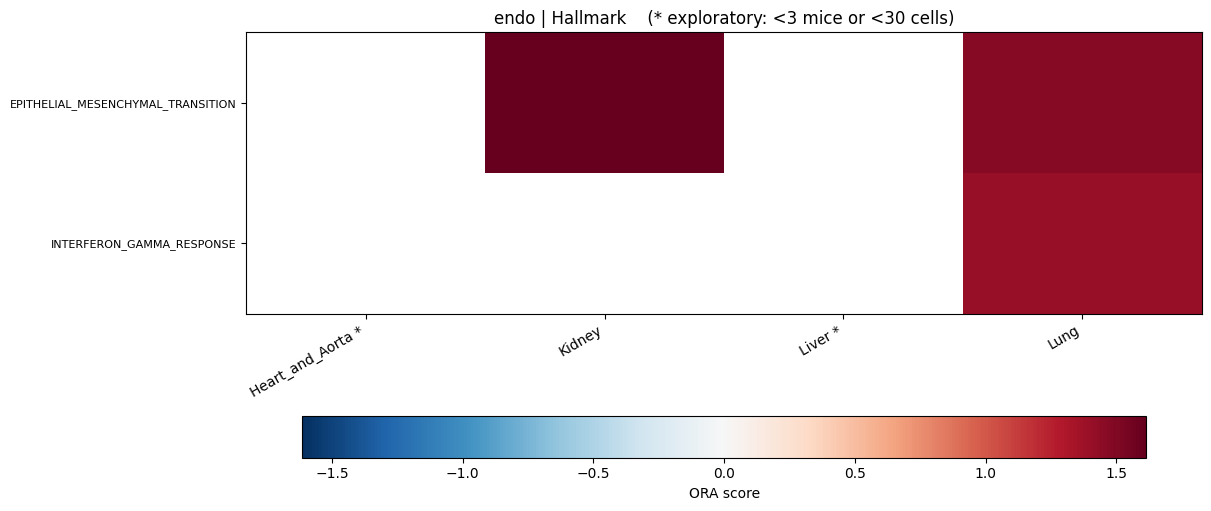

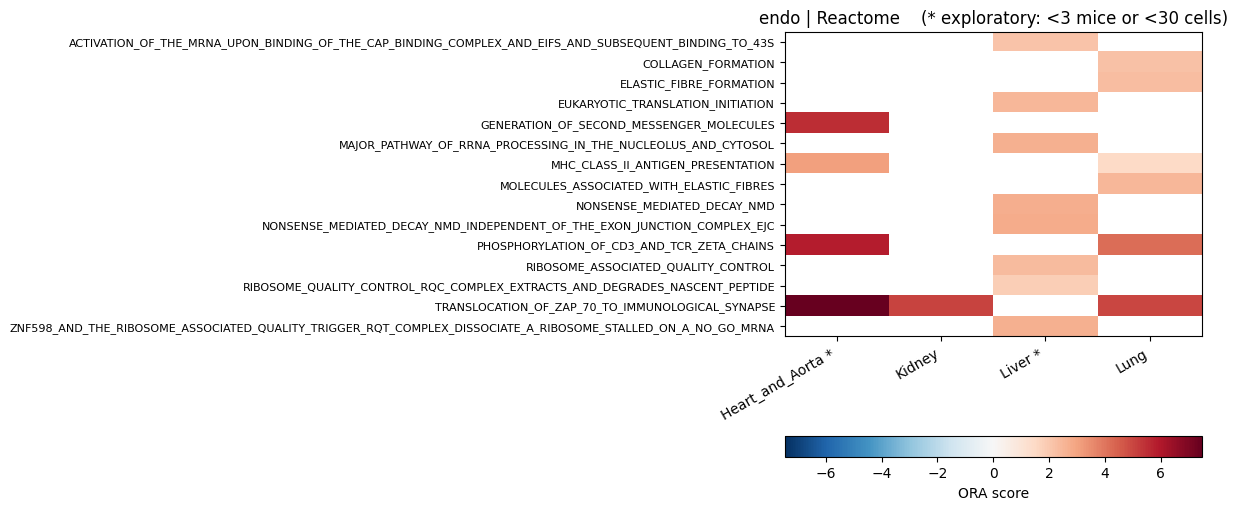

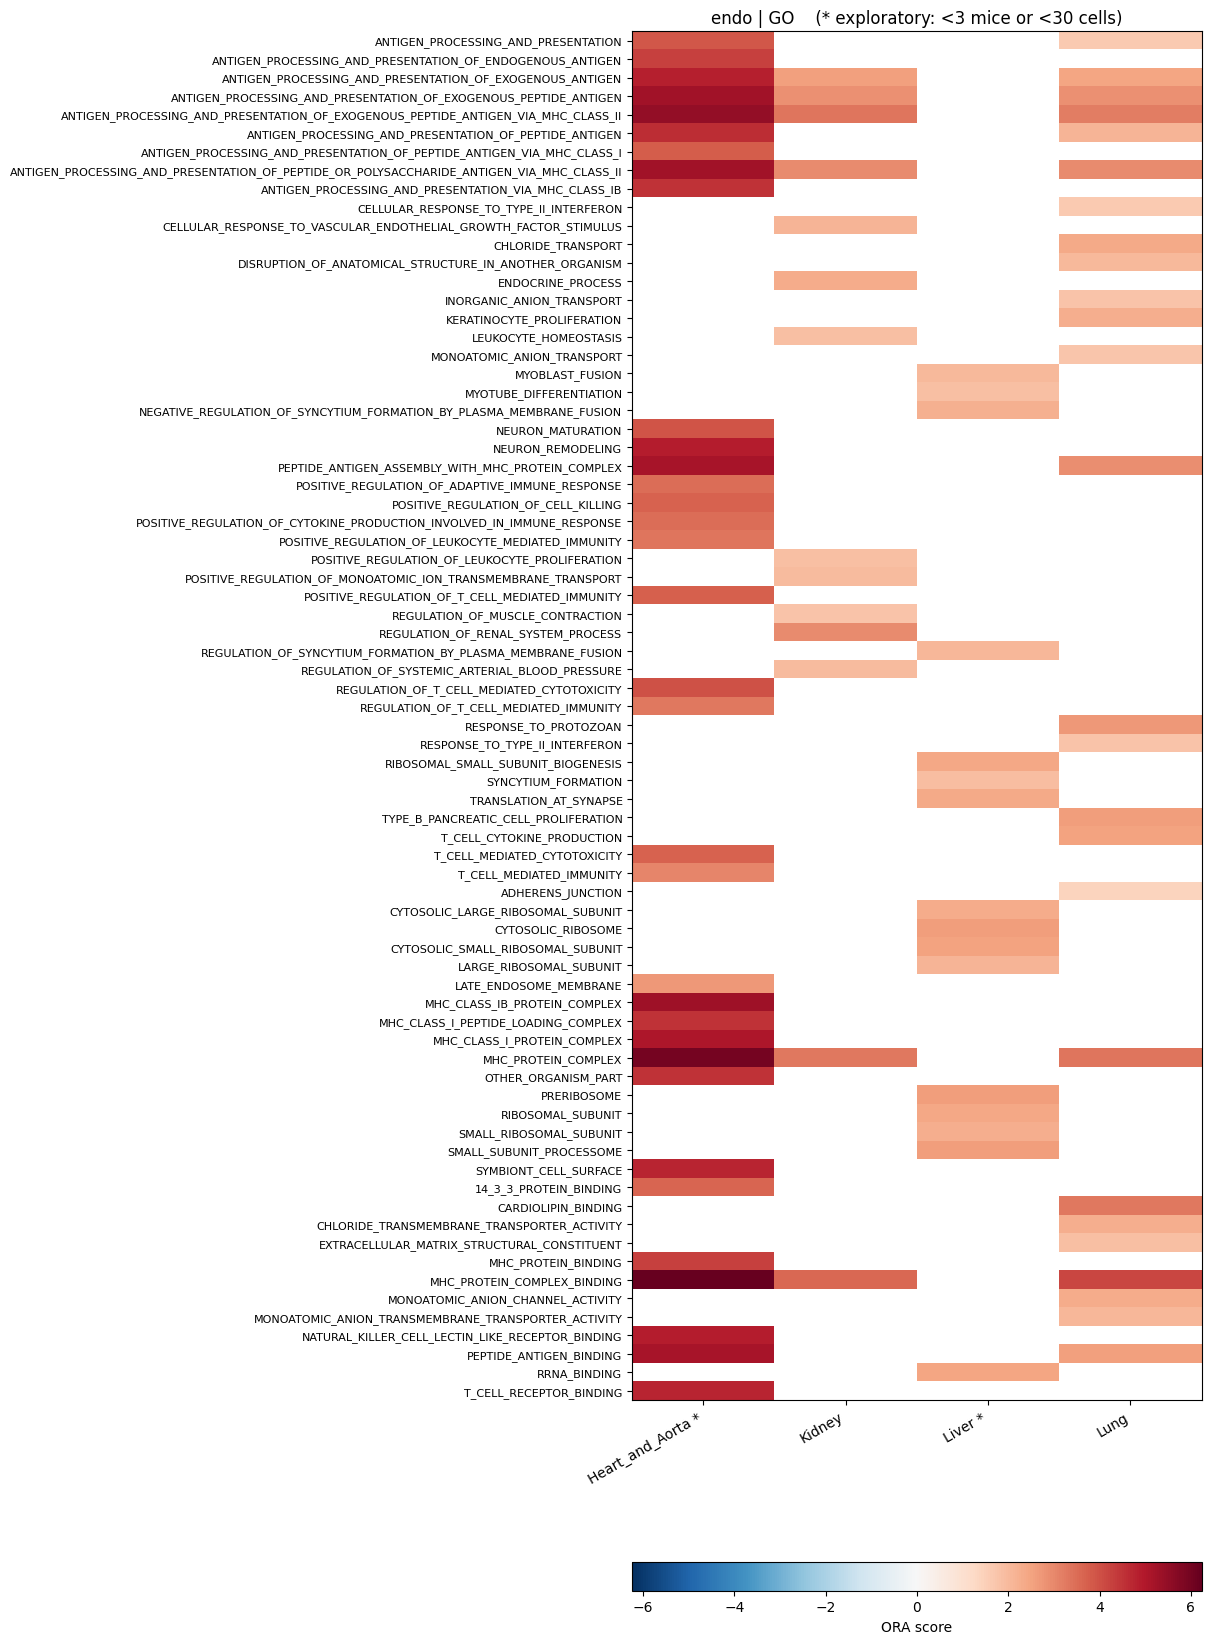

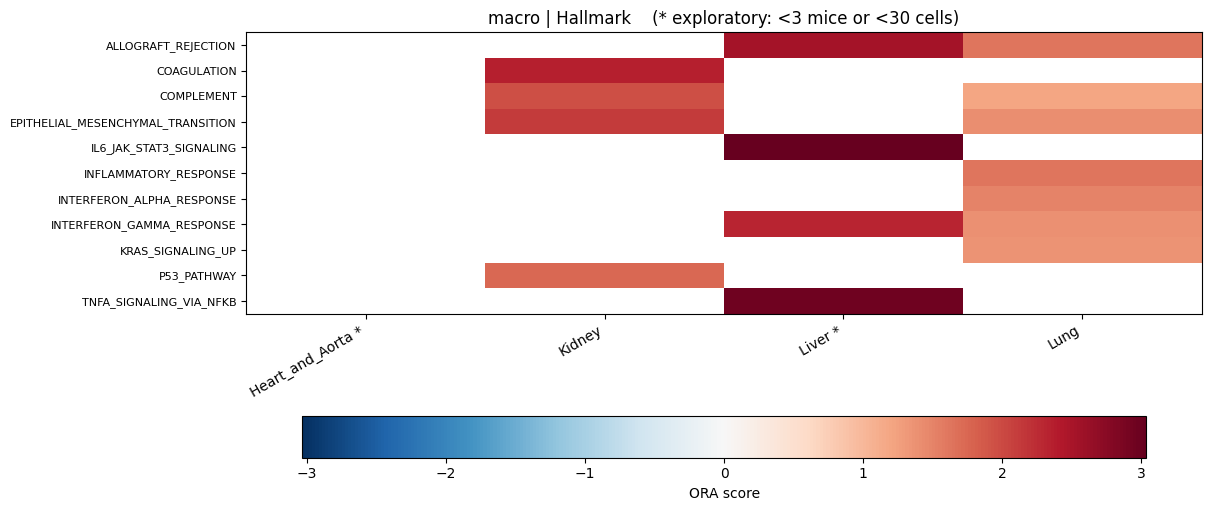

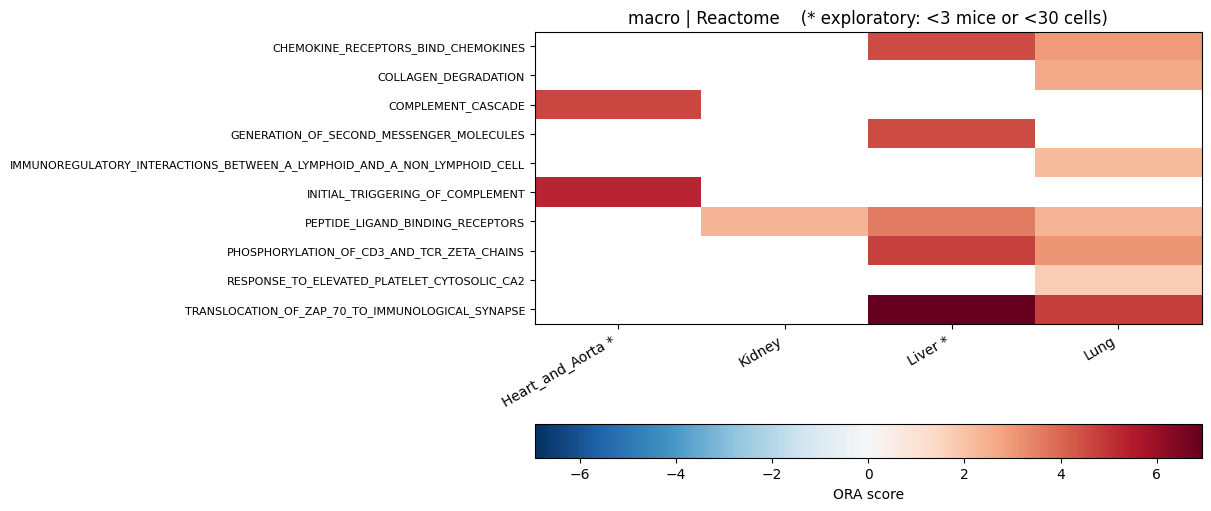

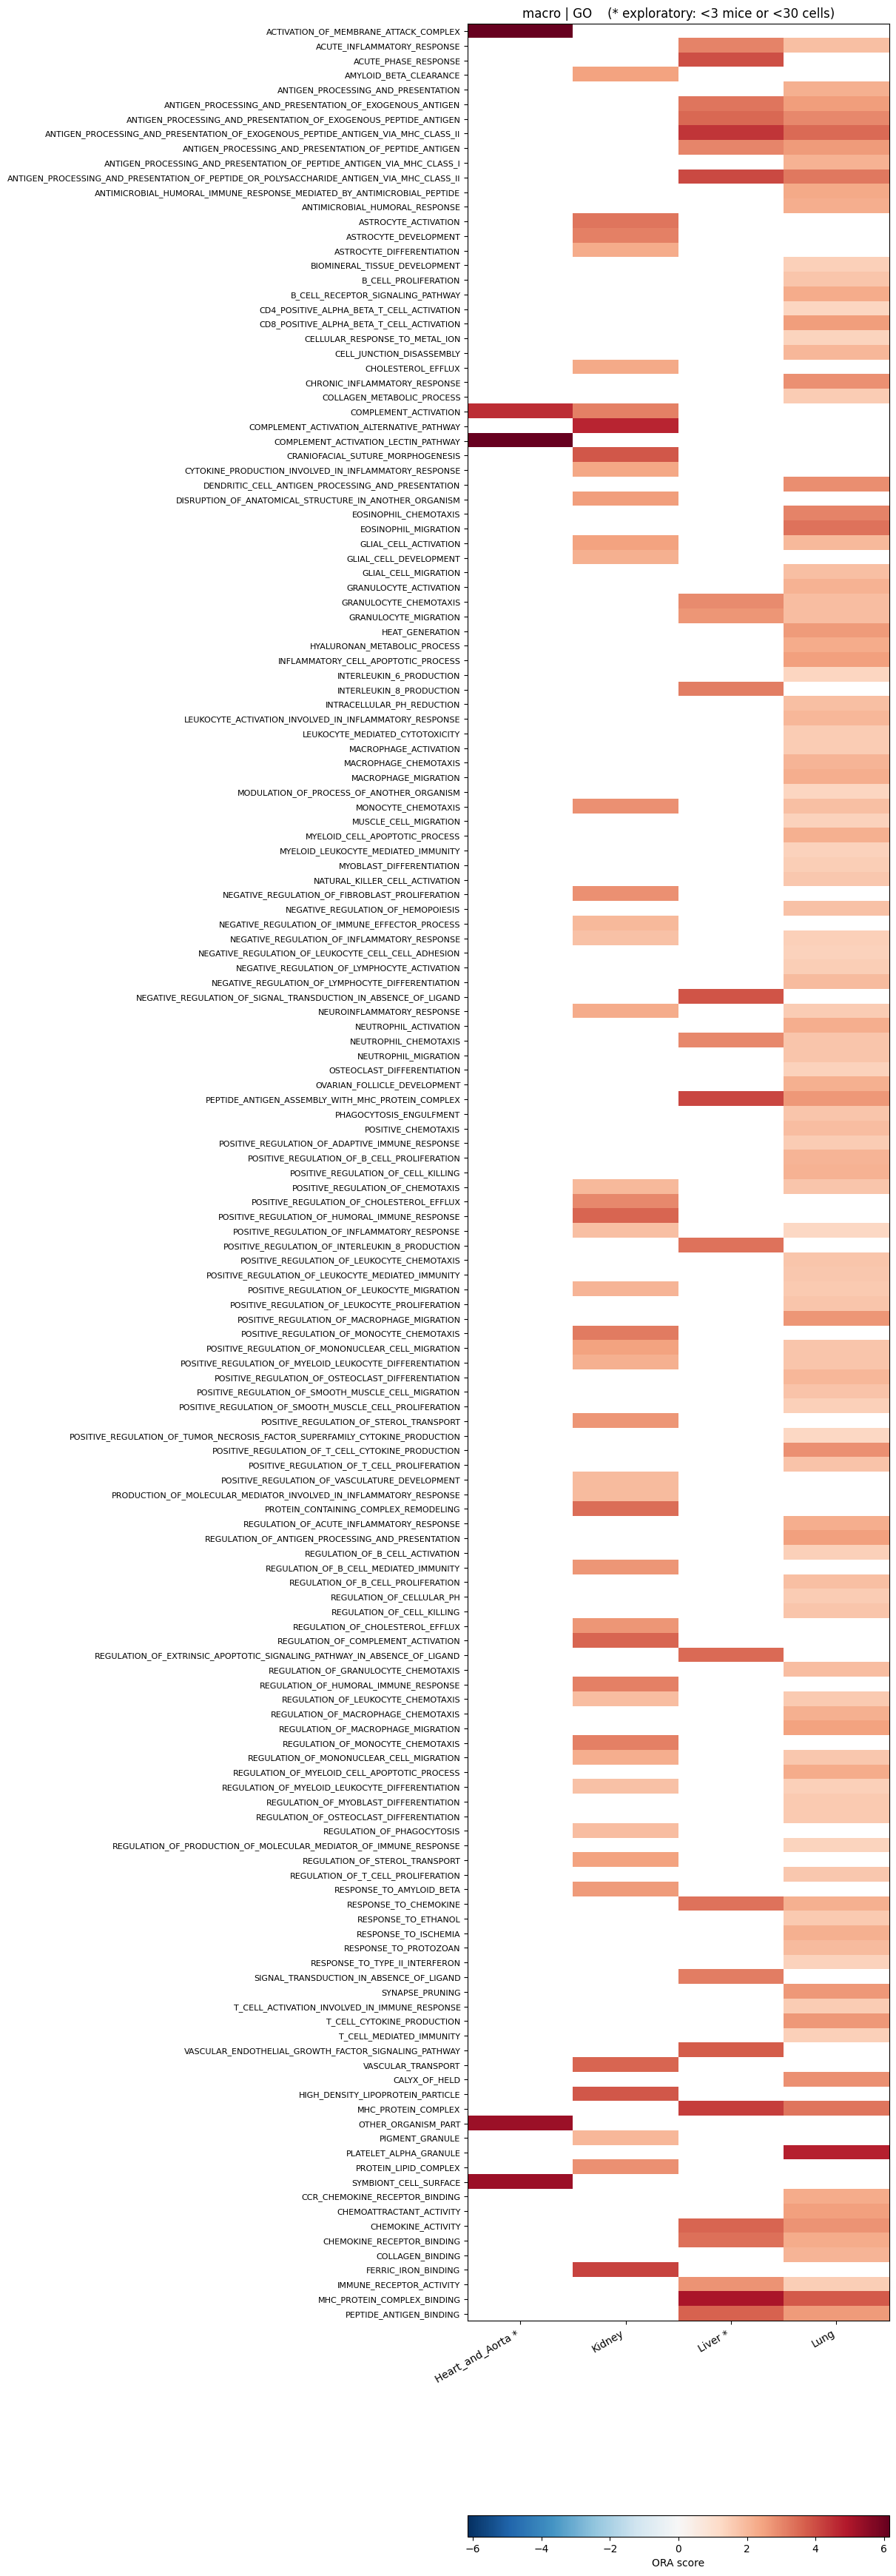

In [ ]:
de_node_summary = pd.read_csv("../results/de_endo_macro/node_summary.tsv", sep="\t")
low_replication = set(zip(
    de_node_summary.loc[de_node_summary["exploratory"], "cell"],
    de_node_summary.loc[de_node_summary["exploratory"], "tissue"],
))

for cell, matrix in ora_matrices.items():
    bh_fdr = matrix["values"][:, :, 0]
    ora_score = matrix["values"][:, :, 1]

    scores = pd.DataFrame(
        np.where((bh_fdr < 0.05) & (ora_score > 0), ora_score, np.nan),
        index=matrix["tissues"],
        columns=matrix["pathways"],
    ).dropna(axis=1, how="all")

    for name, collections in (
        ("Hallmark", ["Hallmark"]),
        ("Reactome", ["Reactome"]),
        ("GO", ["GO:BP", "GO:CC", "GO:MF"]),
    ):
        paths = scores.columns.intersection(
            net.loc[net["collection"].isin(collections), "source"],
            sort=False,
        )
        if paths.empty:
            continue

        labels = paths.str.replace(
            r"^(?:(?:GO:?BP|GO:?CC|GO:?MF|Hallmark|Reactome)[_ |:-]+)+",
            "",
            case=False,
            regex=True,
        )
        plot = scores.loc[:, paths].T
        vmax = plot.max().max()

        fig, ax = plt.subplots(
            figsize=(12, max(5, 0.22 * len(paths))),
            layout="constrained",
        )
        image = ax.imshow(
            plot.to_numpy(),
            aspect="auto",
            interpolation="nearest",
            cmap=plt.get_cmap("RdBu_r").with_extremes(bad="white"),
            vmin=-vmax,
            vmax=vmax,
        )
        ax.set_title(f"{cell} | {name}    (* exploratory: <3 mice or <30 cells)")
        xticklabels = [f"{t} *" if (cell, t) in low_replication else t for t in plot.columns]
        ax.set_xticks(range(plot.shape[1]), xticklabels, rotation=30, ha="right")
        ax.set_yticks(range(len(labels)), labels, fontsize=8)

        fig.colorbar(image, ax=ax, orientation="horizontal", label="ORA score")
        plt.show()

In [12]:
false_positive_paths = {
    ("endo", "Heart_and_Aorta"): {
        "GOBP_NEURON_MATURATION",
        "GOBP_NEURON_REMODELING",
        "GOCC_OTHER_ORGANISM_PART",
        "GOCC_SYMBIONT_CELL_SURFACE",
        "GOBP_POSITIVE_REGULATION_OF_CELL_KILLING",
        "GOBP_T_CELL_MEDIATED_CYTOTOXICITY",
        "GOBP_REGULATION_OF_T_CELL_MEDIATED_CYTOTOXICITY",
        "GOBP_T_CELL_MEDIATED_IMMUNITY",
        "GOBP_REGULATION_OF_T_CELL_MEDIATED_IMMUNITY",
        "GOBP_POSITIVE_REGULATION_OF_T_CELL_MEDIATED_IMMUNITY",
    },
    ("endo", "Liver"): {
        "GOBP_MYOBLAST_FUSION",
        "GOBP_TRANSLATION_AT_SYNAPSE",
        "GOBP_NEGATIVE_REGULATION_OF_SYNCYTIUM_FORMATION_BY_PLASMA_MEMBRANE_FUSION",
        "GOBP_REGULATION_OF_SYNCYTIUM_FORMATION_BY_PLASMA_MEMBRANE_FUSION",
        "GOBP_SYNCYTIUM_FORMATION",
        "GOBP_MYOTUBE_DIFFERENTIATION",
    },
    ("endo", "Lung"): {
        "GOBP_KERATINOCYTE_PROLIFERATION",
        "GOBP_TYPE_B_PANCREATIC_CELL_PROLIFERATION",
        "GOBP_MYOTUBE_DIFFERENTIATION",
        "GOBP_T_CELL_CYTOKINE_PRODUCTION",
        "GOBP_RESPONSE_TO_PROTOZOAN",
        "GOBP_DISRUPTION_OF_ANATOMICAL_STRUCTURE_IN_ANOTHER_ORGANISM",
    },
    ("macro", "Heart_and_Aorta"): {
        "GOCC_OTHER_ORGANISM_PART",
        "GOCC_SYMBIONT_CELL_SURFACE",
    },
    ("macro", "Kidney"): {
        "GOBP_ASTROCYTE_ACTIVATION",
        "GOBP_ASTROCYTE_DEVELOPMENT",
        "GOBP_ASTROCYTE_DIFFERENTIATION",
        "GOBP_GLIAL_CELL_DEVELOPMENT",
        "GOBP_GLIAL_CELL_ACTIVATION",
        "GOBP_CRANIOFACIAL_SUTURE_MORPHOGENESIS",
        "GOBP_NEUROINFLAMMATORY_RESPONSE",
        "GOBP_VASCULAR_TRANSPORT",
        "GOCC_PIGMENT_GRANULE",
    },
    ("macro", "Liver"): {
        "GOBP_NEGATIVE_REGULATION_OF_SIGNAL_TRANSDUCTION_IN_ABSENCE_OF_LIGAND",
        "GOBP_REGULATION_OF_EXTRINSIC_APOPTOTIC_SIGNALING_PATHWAY_IN_ABSENCE_OF_LIGAND",
        "GOBP_INTERLEUKIN_8_PRODUCTION",
        "GOBP_POSITIVE_REGULATION_OF_INTERLEUKIN_8_PRODUCTION",
        "GOBP_SIGNAL_TRANSDUCTION_IN_ABSENCE_OF_LIGAND",
    },
    ("macro", "Lung"): {
        "GOBP_GLIAL_CELL_MIGRATION",
        "GOBP_GLIAL_CELL_ACTIVATION",
        "GOBP_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_REGULATION_OF_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_POSITIVE_REGULATION_OF_OSTEOCLAST_DIFFERENTIATION",
        "GOBP_OVARIAN_FOLLICLE_DEVELOPMENT",
        "GOCC_CALYX_OF_HELD",
        "GOCC_PLATELET_ALPHA_GRANULE",
        "GOBP_MYOBLAST_DIFFERENTIATION",
        "GOBP_REGULATION_OF_MYOBLAST_DIFFERENTIATION",
        "GOBP_POSITIVE_REGULATION_OF_SMOOTH_MUSCLE_CELL_MIGRATION",
        "GOBP_HEAT_GENERATION",
        "GOBP_SYNAPSE_PRUNING",
        "GOBP_NEUROINFLAMMATORY_RESPONSE",
        "GOBP_BIOMINERAL_TISSUE_DEVELOPMENT",
        "GOBP_CELL_JUNCTION_DISASSEMBLY",
        "GOBP_T_CELL_CYTOKINE_PRODUCTION",
        "GOBP_POSITIVE_REGULATION_OF_T_CELL_CYTOKINE_PRODUCTION",
        "GOBP_DENDRITIC_CELL_ANTIGEN_PROCESSING_AND_PRESENTATION",
        "GOBP_RESPONSE_TO_ETHANOL",
        "GOBP_RESPONSE_TO_ISCHEMIA",
        "GOBP_MUSCLE_CELL_MIGRATION",
        "GOBP_POSITIVE_REGULATION_OF_SMOOTH_MUSCLE_CELL_PROLIFERATION",
        "GOBP_RESPONSE_TO_PROTOZOAN",
    },
}

redundant_pathways = {
    "GOBP_REGULATION_OF_MONONUCLEAR_CELL_MIGRATION",
    "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_MIGRATION",
    "GOBP_POSITIVE_REGULATION_OF_CHEMOTAXIS",
    "GOBP_NEGATIVE_REGULATION_OF_INFLAMMATORY_RESPONSE",
    "GOBP_POSITIVE_REGULATION_OF_INFLAMMATORY_RESPONSE",
    "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_MEDIATED_IMMUNITY",
    "GOMF_COLLAGEN_BINDING",
    "GOBP_DISRUPTION_OF_ANATOMICAL_STRUCTURE_IN_ANOTHER_ORGANISM",
    "GOBP_MODULATION_OF_PROCESS_OF_ANOTHER_ORGANISM",
    "GOBP_POSITIVE_REGULATION_OF_MONONUCLEAR_CELL_MIGRATION",
    "GOBP_NEGATIVE_REGULATION_OF_HEMOPOIESIS",
    "GOBP_REGULATION_OF_STEROL_TRANSPORT",
    "GOBP_PROTEIN_CONTAINING_COMPLEX_REMODELING",
    "GOBP_PRODUCTION_OF_MOLECULAR_MEDIATOR_INVOLVED_IN_INFLAMMATORY_RESPONSE",
    "GOBP_REGULATION_OF_PRODUCTION_OF_MOLECULAR_MEDIATOR_OF_IMMUNE_RESPONSE",
    "GOBP_NEGATIVE_REGULATION_OF_IMMUNE_EFFECTOR_PROCESS",
    "GOBP_PHAGOCYTOSIS_ENGULFMENT",
    "GOMF_PEPTIDE_ANTIGEN_BINDING",
    "GOMF_MHC_PROTEIN_COMPLEX_BINDING",
    "GOBP_LEUKOCYTE_MEDIATED_CYTOTOXICITY",
    "GOBP_POSITIVE_REGULATION_OF_STEROL_TRANSPORT",
    "GOBP_CYTOKINE_PRODUCTION_INVOLVED_IN_INFLAMMATORY_RESPONSE",
    "GOBP_NEGATIVE_REGULATION_OF_LYMPHOCYTE_ACTIVATION",
    "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_PROLIFERATION",
    "GOBP_T_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE",
    "GOBP_RESPONSE_TO_AMYLOID_BETA",
    "GOBP_LEUKOCYTE_ACTIVATION_INVOLVED_IN_INFLAMMATORY_RESPONSE",
    "GOBP_POSITIVE_CHEMOTAXIS",
}

In [13]:
go_parent_map = {
    "endo": {
        # Antigen processing and presentation
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_ENDOGENOUS_ANTIGEN": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_EXOGENOUS_ANTIGEN": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_ANTIGEN": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_OR_POLYSACCHARIDE_ANTIGEN_VIA_MHC_CLASS_II": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_VIA_MHC_CLASS_IB": "GO:0019882",

        # Antigen processing and presentation of peptide antigen
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_EXOGENOUS_PEPTIDE_ANTIGEN": "GO:0048002",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_ANTIGEN_VIA_MHC_CLASS_I": "GO:0048002",

        # Immune system process
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION": "GO:0002376",
        "GOBP_LEUKOCYTE_HOMEOSTASIS": "GO:0002376",

        # MHC protein complex
        "GOCC_MHC_CLASS_IB_PROTEIN_COMPLEX": "GO:0042611",
        "GOCC_MHC_CLASS_I_PROTEIN_COMPLEX": "GO:0042611",

        # Ribonucleoprotein complex
        "GOCC_PRERIBOSOME": "GO:1990904",
        "GOCC_RIBOSOMAL_SUBUNIT": "GO:1990904",

        # Ribosomal subunit
        "GOCC_LARGE_RIBOSOMAL_SUBUNIT": "GO:0044391",
        "GOCC_SMALL_RIBOSOMAL_SUBUNIT": "GO:0044391",

        # Signaling receptor binding
        "GOMF_MHC_PROTEIN_BINDING": "GO:0005102",
        "GOMF_NATURAL_KILLER_CELL_LECTIN_LIKE_RECEPTOR_BINDING": "GO:0005102",
        "GOMF_T_CELL_RECEPTOR_BINDING": "GO:0005102",

        # Monoatomic anion transmembrane transporter activity
        "GOMF_CHLORIDE_TRANSMEMBRANE_TRANSPORTER_ACTIVITY": "GO:0008509",
        "GOMF_MONOATOMIC_ANION_CHANNEL_ACTIVITY": "GO:0008509",
    },

    "macro": {
        # Antigen processing and presentation
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_EXOGENOUS_ANTIGEN": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_ANTIGEN": "GO:0019882",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_OR_POLYSACCHARIDE_ANTIGEN_VIA_MHC_CLASS_II": "GO:0019882",

        # Antigen processing and presentation of peptide antigen
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_EXOGENOUS_PEPTIDE_ANTIGEN": "GO:0048002",
        "GOBP_ANTIGEN_PROCESSING_AND_PRESENTATION_OF_PEPTIDE_ANTIGEN_VIA_MHC_CLASS_I": "GO:0048002",

        # Complement activation
        "GOBP_ACTIVATION_OF_MEMBRANE_ATTACK_COMPLEX": "GO:0006956",
        "GOBP_COMPLEMENT_ACTIVATION_ALTERNATIVE_PATHWAY": "GO:0006956",
        "GOBP_COMPLEMENT_ACTIVATION_LECTIN_PATHWAY": "GO:0006956",

        # Humoral immune response
        "GOBP_ANTIMICROBIAL_HUMORAL_RESPONSE": "GO:0006959",
        "GOBP_COMPLEMENT_ACTIVATION": "GO:0006959",

        # Regulation of humoral immune response
        "GOBP_POSITIVE_REGULATION_OF_HUMORAL_IMMUNE_RESPONSE": "GO:0002920",
        "GOBP_REGULATION_OF_COMPLEMENT_ACTIVATION": "GO:0002920",

        # Regulation of immune effector process
        "GOBP_NEGATIVE_REGULATION_OF_IMMUNE_EFFECTOR_PROCESS": "GO:0002697",
        "GOBP_REGULATION_OF_PRODUCTION_OF_MOLECULAR_MEDIATOR_OF_IMMUNE_RESPONSE": "GO:0002697",

        # Inflammatory response
        "GOBP_ACUTE_INFLAMMATORY_RESPONSE": "GO:0006954",
        "GOBP_CHRONIC_INFLAMMATORY_RESPONSE": "GO:0006954",

        # Regulation of inflammatory response
        "GOBP_NEGATIVE_REGULATION_OF_INFLAMMATORY_RESPONSE": "GO:0050727",
        "GOBP_POSITIVE_REGULATION_OF_INFLAMMATORY_RESPONSE": "GO:0050727",
        "GOBP_REGULATION_OF_ACUTE_INFLAMMATORY_RESPONSE": "GO:0050727",

        # Cytokine production
        "GOBP_CYTOKINE_PRODUCTION_INVOLVED_IN_INFLAMMATORY_RESPONSE": "GO:0001816",
        "GOBP_INTERLEUKIN_6_PRODUCTION": "GO:0001816",

        # Response to cytokine
        "GOBP_RESPONSE_TO_CHEMOKINE": "GO:0034097",
        "GOBP_RESPONSE_TO_TYPE_II_INTERFERON": "GO:0034097",

        # Regulation of leukocyte chemotaxis
        "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_CHEMOTAXIS": "GO:0002688",
        "GOBP_REGULATION_OF_GRANULOCYTE_CHEMOTAXIS": "GO:0002688",
        "GOBP_REGULATION_OF_MACROPHAGE_CHEMOTAXIS": "GO:0002688",
        "GOBP_REGULATION_OF_MONOCYTE_CHEMOTAXIS": "GO:0002688",

        # Regulation of chemotaxis
        "GOBP_POSITIVE_REGULATION_OF_CHEMOTAXIS": "GO:0050920",
        "GOBP_REGULATION_OF_LEUKOCYTE_CHEMOTAXIS": "GO:0050920",

        # Leukocyte chemotaxis
        "GOBP_GRANULOCYTE_CHEMOTAXIS": "GO:0030595",
        "GOBP_MACROPHAGE_CHEMOTAXIS": "GO:0030595",
        "GOBP_MONOCYTE_CHEMOTAXIS": "GO:0030595",

        # Granulocyte chemotaxis
        "GOBP_EOSINOPHIL_CHEMOTAXIS": "GO:0071621",
        "GOBP_NEUTROPHIL_CHEMOTAXIS": "GO:0071621",

        # Granulocyte migration
        "GOBP_EOSINOPHIL_MIGRATION": "GO:0097530",
        "GOBP_NEUTROPHIL_MIGRATION": "GO:0097530",

        # Myeloid leukocyte migration
        "GOBP_GRANULOCYTE_MIGRATION": "GO:0097529",
        "GOBP_MACROPHAGE_MIGRATION": "GO:0097529",

        # Regulation of leukocyte migration
        "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_MIGRATION": "GO:0002685",
        "GOBP_REGULATION_OF_MONONUCLEAR_CELL_MIGRATION": "GO:0002685",

        # Regulation of mononuclear cell migration
        "GOBP_POSITIVE_REGULATION_OF_MONONUCLEAR_CELL_MIGRATION": "GO:0071675",
        "GOBP_REGULATION_OF_MACROPHAGE_MIGRATION": "GO:0071675",

        # Positive regulation of mononuclear cell migration
        "GOBP_POSITIVE_REGULATION_OF_MACROPHAGE_MIGRATION": "GO:0071677",
        "GOBP_POSITIVE_REGULATION_OF_MONOCYTE_CHEMOTAXIS": "GO:0071677",

        # Alpha-beta T cell activation
        "GOBP_CD4_POSITIVE_ALPHA_BETA_T_CELL_ACTIVATION": "GO:0046631",
        "GOBP_CD8_POSITIVE_ALPHA_BETA_T_CELL_ACTIVATION": "GO:0046631",

        # Regulation of lymphocyte activation
        "GOBP_NEGATIVE_REGULATION_OF_LYMPHOCYTE_ACTIVATION": "GO:0051249",
        "GOBP_REGULATION_OF_B_CELL_ACTIVATION": "GO:0051249",

        # Regulation of lymphocyte proliferation
        "GOBP_REGULATION_OF_B_CELL_PROLIFERATION": "GO:0050670",
        "GOBP_REGULATION_OF_T_CELL_PROLIFERATION": "GO:0050670",

        # Positive regulation of lymphocyte proliferation
        "GOBP_POSITIVE_REGULATION_OF_B_CELL_PROLIFERATION": "GO:0050671",
        "GOBP_POSITIVE_REGULATION_OF_T_CELL_PROLIFERATION": "GO:0050671",

        # Positive regulation of cell population proliferation
        "GOBP_POSITIVE_REGULATION_OF_LEUKOCYTE_PROLIFERATION": "GO:0008284",
        "GOBP_POSITIVE_REGULATION_OF_SMOOTH_MUSCLE_CELL_PROLIFERATION": "GO:0008284",

        # Leukocyte mediated immunity
        "GOBP_LEUKOCYTE_MEDIATED_CYTOTOXICITY": "GO:0002443",
        "GOBP_MYELOID_LEUKOCYTE_MEDIATED_IMMUNITY": "GO:0002443",

        # Myeloid leukocyte activation
        "GOBP_GRANULOCYTE_ACTIVATION": "GO:0002274",
        "GOBP_MACROPHAGE_ACTIVATION": "GO:0002274",

        # Apoptotic process
        "GOBP_INFLAMMATORY_CELL_APOPTOTIC_PROCESS": "GO:0006915",
        "GOBP_MYELOID_CELL_APOPTOTIC_PROCESS": "GO:0006915",

        # Interspecies interaction
        "GOBP_DISRUPTION_OF_ANATOMICAL_STRUCTURE_IN_ANOTHER_ORGANISM": "GO:0044419",
        "GOBP_MODULATION_OF_PROCESS_OF_ANOTHER_ORGANISM": "GO:0044419",

        # Multicellular organismal process
        "GOBP_AMYLOID_BETA_CLEARANCE": "GO:0032501",
        "GOBP_PRODUCTION_OF_MOLECULAR_MEDIATOR_INVOLVED_IN_INFLAMMATORY_RESPONSE": "GO:0032501",

        # Chemokine receptor binding
        "GOMF_CCR_CHEMOKINE_RECEPTOR_BINDING": "GO:0042379",
        "GOMF_CHEMOKINE_ACTIVITY": "GO:0042379",

        # Protein-containing complex binding
        "GOMF_COLLAGEN_BINDING": "GO:0044877",
        "GOMF_MHC_PROTEIN_COMPLEX_BINDING": "GO:0044877",
    },
}

In [14]:
def drop_go_regulation_redundancy(plot):
    terms = plot.index
    activity = terms.str.replace(
        r"^GOBP_(?:POSITIVE_|NEGATIVE_)?REGULATION_OF_",
        "GOBP_",
        regex=True,
    )
    regulation = activity.str.replace("^GOBP_", "GOBP_REGULATION_OF_", regex=True)
    directional = terms.str.match(r"^GOBP_(?:POSITIVE|NEGATIVE)_REGULATION_OF_")

    redundant = ((terms != activity) & activity.isin(terms)) | (
        directional & regulation.isin(terms)
    )
    return plot.loc[~redundant]

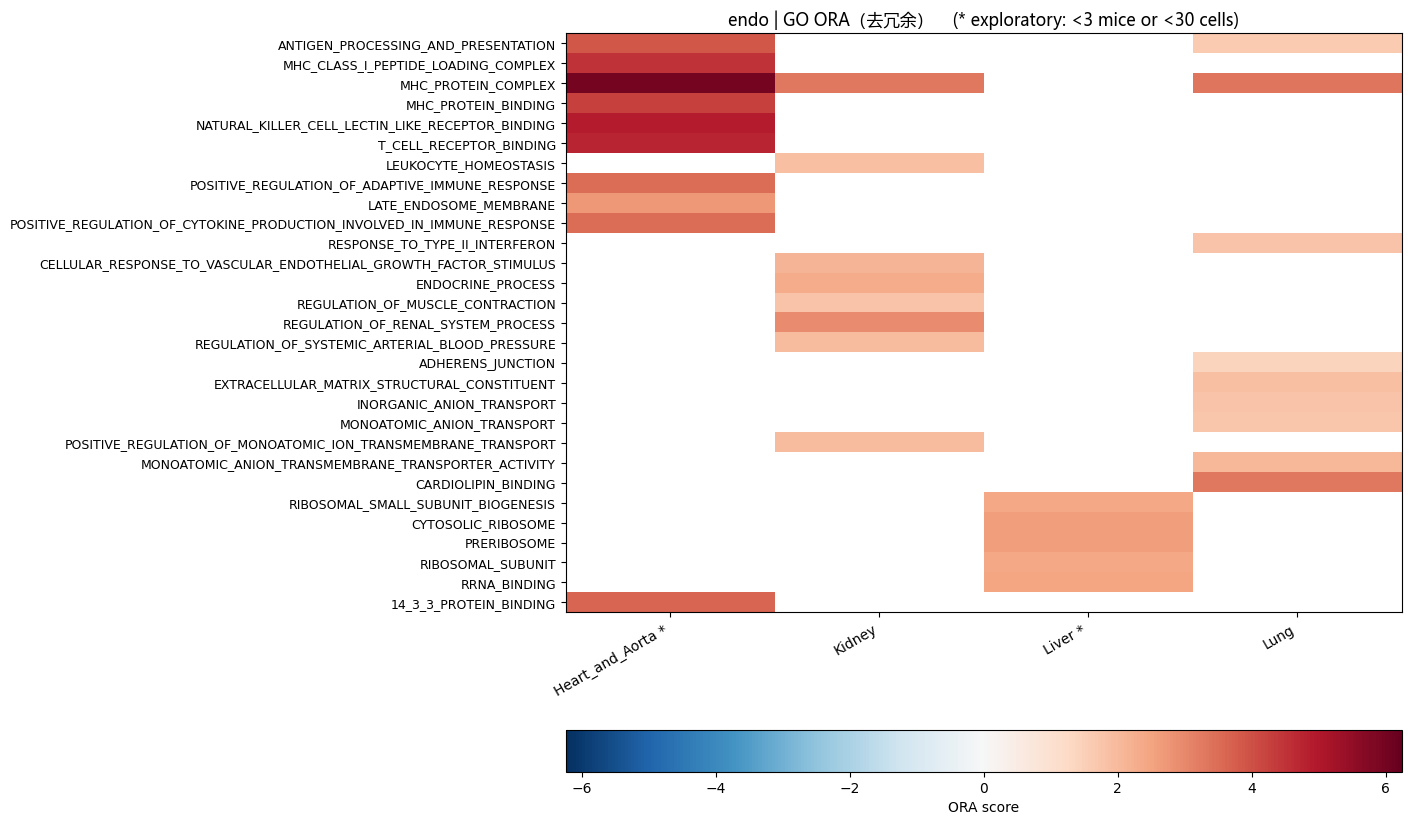

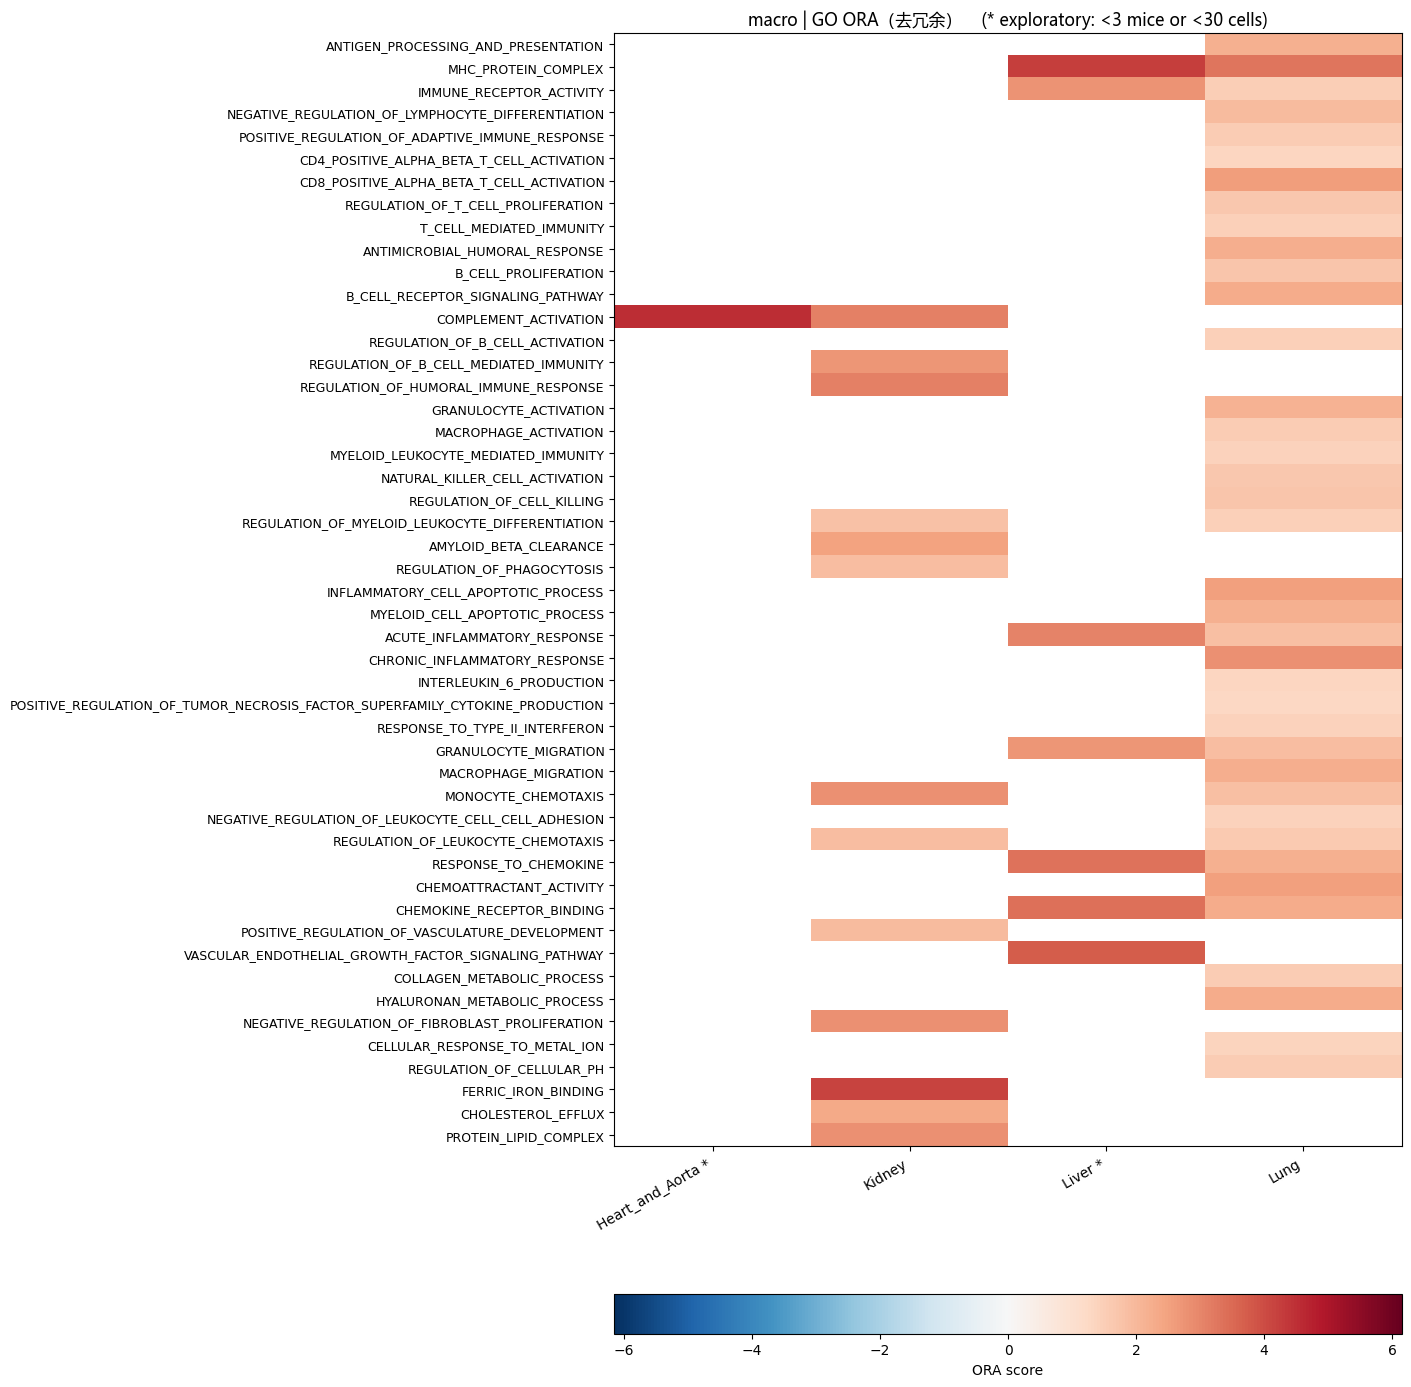

In [ ]:
import re
import sqlite3

go_paths = net.loc[
    net["collection"].isin(["GO:BP", "GO:CC", "GO:MF"]), "source"
]

db = sqlite3.connect(
    "file:../data_interim/go/GO.db_3.23.1.sqlite?mode=ro&immutable=1",
    uri=True,
)
go_ids = {
    f"GO{namespace}_{re.sub(r'[^A-Z0-9]+', '_', name.upper()).strip('_')}": term_id
    for term_id, name, namespace in db.execute(
        "SELECT _id, term, ontology FROM go_term"
    )
}

go_parents = {}
for namespace in ("bp", "cc", "mf"):
    for child, parent in db.execute(
        f"""SELECT _id, _parent_id FROM go_{namespace}_parents
            WHERE relationship_type IN ('isa', 'part of')"""
    ):
        go_parents.setdefault(child, set()).add(parent)
db.close()


def has_retained_ancestor(term_id, retained_ids):
    checked = {term_id}
    pending = list(go_parents.get(term_id, ()))

    while pending:
        parent = pending.pop()
        if parent in checked:
            continue
        if parent in retained_ids:
            return True
        checked.add(parent)
        pending.extend(go_parents.get(parent, ()))

    return False


def plot_go_heatmap(cell, matrix):
    bh_fdr = matrix["values"][:, :, 0]
    ora_score = matrix["values"][:, :, 1]
    scores = pd.DataFrame(
        np.where((bh_fdr < 0.05) & (ora_score > 0), ora_score, np.nan),
        index=matrix["tissues"],
        columns=matrix["pathways"],
    )
    scores = scores.loc[:, scores.columns.intersection(go_paths, sort=False)]
    vmax = scores.max().max()

    for tissue in scores.index:
        flagged = false_positive_paths.get((cell, tissue), ())
        scores.loc[tissue, scores.columns.isin(flagged)] = np.nan

    scores.loc[:, scores.columns.isin(redundant_pathways)] = np.nan

    plot = scores.dropna(axis=1, how="all").T
    if plot.empty:
        return

    # 同一活动优先保留本体，其次保留普通调节。
    terms = plot.index
    activity = terms.str.replace(
        r"^GOBP_(?:POSITIVE_|NEGATIVE_)?REGULATION_OF_", "GOBP_", regex=True
    )
    regulation = activity.str.replace("^GOBP_", "GOBP_REGULATION_OF_", regex=True)
    directional = terms.str.match(r"^GOBP_(?:POSITIVE_|NEGATIVE_)REGULATION_OF_")
    redundant = ((terms != activity) & activity.isin(terms)) | (
        directional & regulation.isin(terms)
    )
    plot = plot.loc[~redundant]

    # 沿 GO 父链查找已保留的上位条目，只画代表行。
    term_ids = [go_ids.get(term) for term in plot.index]
    retained_ids = set(term_ids) - {None}
    plot = plot.loc[
        [not has_retained_ancestor(term_id, retained_ids) for term_id in term_ids]
    ]

    # 按功能排列热图行，组内保留原来的顺序。
    functional_groups = (
        r"ANTIGEN|MHC_|T_CELL_RECEPTOR|NATURAL_KILLER_CELL_LECTIN_LIKE_RECEPTOR|IMMUNE_RECEPTOR",
        r"ADAPTIVE_IMMUNE|LYMPHOCYTE|LEUKOCYTE_(?:HOMEOSTASIS|PROLIFERATION)",
        r"_T_CELL_",
        r"_B_CELL_|HUMORAL|COMPLEMENT",
        r"GRANULOCYTE_ACTIVATION|MACROPHAGE_ACTIVATION|MYELOID_LEUKOCYTE|NATURAL_KILLER_CELL_ACTIVATION|CELL_KILLING",
        r"AMYLOID|PHAGOCYTOSIS|LATE_ENDOSOME",
        r"APOPTOTIC",
        r"INFLAMMATORY|CYTOKINE|INTERLEUKIN|INTERFERON",
        r"CHEMOTAXIS|CHEMOKINE|CHEMOATTRACTANT|(?:GRANULOCYTE|MACROPHAGE)_MIGRATION|LEUKOCYTE_CELL_CELL_ADHESION",
        r"VASCULAR|VASCULATURE|BLOOD_PRESSURE|MUSCLE_CONTRACTION|RENAL_SYSTEM|ENDOCRINE",
        r"EXTRACELLULAR_MATRIX|COLLAGEN|HYALURONAN|ADHERENS_JUNCTION|FIBROBLAST",
        r"TRANSPORT|CELLULAR_PH|METAL_ION|IRON_BINDING",
        r"CARDIOLIPIN|CHOLESTEROL|PROTEIN_LIPID",
        r"RIBOSOM|RRNA_BINDING",
    )
    plot = plot.loc[
        sorted(
            plot.index,
            key=lambda term: next(
                (i for i, pattern in enumerate(functional_groups) if re.search(pattern, term)),
                len(functional_groups),
            ),
        )
    ]
    labels = plot.index.str.replace(r"^GO(?:BP|CC|MF)_", "", regex=True)
    fig, ax = plt.subplots(
        figsize=(14, max(8, 0.28 * len(plot))),
        layout="constrained",
    )
    image = ax.imshow(
        plot.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap=plt.get_cmap("RdBu_r").with_extremes(bad="white"),
        vmin=-vmax,
        vmax=vmax,
    )
    ax.set_title(f"{cell} | GO ORA（去冗余）    (* exploratory: <3 mice or <30 cells)", fontfamily="Microsoft YaHei", fontsize=12)
    xticklabels = [f"{t} *" if (cell, t) in low_replication else t for t in plot.columns]
    ax.set_xticks(range(plot.shape[1]), xticklabels, rotation=30, ha="right", fontsize=10)
    ax.set_yticks(range(len(plot)), labels, fontsize=9)
    fig.colorbar(image, ax=ax, orientation="horizontal", label="ORA score")
    plt.show()


for cell, matrix in ora_matrices.items():
    plot_go_heatmap(cell, matrix)